In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/home-credit-default-risk/sample_submission.csv
/kaggle/input/competitions/home-credit-default-risk/bureau_balance.csv
/kaggle/input/competitions/home-credit-default-risk/POS_CASH_balance.csv
/kaggle/input/competitions/home-credit-default-risk/application_train.csv
/kaggle/input/competitions/home-credit-default-risk/HomeCredit_columns_description.csv
/kaggle/input/competitions/home-credit-default-risk/application_test.csv
/kaggle/input/competitions/home-credit-default-risk/previous_application.csv
/kaggle/input/competitions/home-credit-default-risk/credit_card_balance.csv
/kaggle/input/competitions/home-credit-default-risk/installments_payments.csv
/kaggle/input/competitions/home-credit-default-risk/bureau.csv


**read the dataset**

In [6]:
df= pd.read_csv("/kaggle/input/competitions/home-credit-default-risk/application_train.csv")


# split columnes by dtypes

In [62]:
yes_no_cols = [
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "FLAG_MOBIL",
    "FLAG_EMP_PHONE",
    "FLAG_WORK_PHONE",
    "FLAG_CONT_MOBILE",
    "FLAG_PHONE",
    "FLAG_EMAIL",
    "EMERGENCYSTATE_MODE"
]
binary_cols = [
   

    "REG_REGION_NOT_LIVE_REGION",
    "REG_REGION_NOT_WORK_REGION",
    "LIVE_REGION_NOT_WORK_REGION",
    "REG_CITY_NOT_LIVE_CITY",
    "REG_CITY_NOT_WORK_CITY",
    "LIVE_CITY_NOT_WORK_CITY",

    "FLAG_DOCUMENT_2",
    "FLAG_DOCUMENT_3",
    "FLAG_DOCUMENT_4",
    "FLAG_DOCUMENT_5",
    "FLAG_DOCUMENT_6",
    "FLAG_DOCUMENT_7",
    "FLAG_DOCUMENT_8",
    "FLAG_DOCUMENT_9",
    "FLAG_DOCUMENT_10",
    "FLAG_DOCUMENT_11",
    "FLAG_DOCUMENT_12",
    "FLAG_DOCUMENT_13",
    "FLAG_DOCUMENT_14",
    "FLAG_DOCUMENT_15",
    "FLAG_DOCUMENT_16",
    "FLAG_DOCUMENT_17",
    "FLAG_DOCUMENT_18",
    "FLAG_DOCUMENT_19",
    "FLAG_DOCUMENT_20",
    "FLAG_DOCUMENT_21"
]
to_binary=[ "NAME_CONTRACT_TYPE",
    "CODE_GENDER"]
numeric_cols = [
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "REGION_POPULATION_RELATIVE",
    "AGE_YEARS",
    "YEAR_EMPLOYED",
    "YEAR_REGESTRATION",
    "YEAR_ID_PUBLISH",
    "OWN_CAR_AGE",
    "CNT_FAM_MEMBERS",
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY",
    "HOUR_APPR_PROCESS_START",

    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",

    "APARTMENTS_AVG",
    "BASEMENTAREA_AVG",
    "YEARS_BEGINEXPLUATATION_AVG",
    "YEARS_BUILD_AVG",
    "COMMONAREA_AVG",
    "ELEVATORS_AVG",
    "ENTRANCES_AVG",
    "FLOORSMAX_AVG",
    "FLOORSMIN_AVG",
    "LANDAREA_AVG",
    "LIVINGAPARTMENTS_AVG",
    "LIVINGAREA_AVG",
    "NONLIVINGAPARTMENTS_AVG",
    "NONLIVINGAREA_AVG",

    "APARTMENTS_MODE",
    "BASEMENTAREA_MODE",
    "YEARS_BEGINEXPLUATATION_MODE",
    "YEARS_BUILD_MODE",
    "COMMONAREA_MODE",
    "ELEVATORS_MODE",
    "ENTRANCES_MODE",
    "FLOORSMAX_MODE",
    "FLOORSMIN_MODE",
    "LANDAREA_MODE",
    "LIVINGAPARTMENTS_MODE",
    "LIVINGAREA_MODE",
    "NONLIVINGAPARTMENTS_MODE",
    "NONLIVINGAREA_MODE",

    "APARTMENTS_MEDI",
    "BASEMENTAREA_MEDI",
    "YEARS_BEGINEXPLUATATION_MEDI",
    "YEARS_BUILD_MEDI",
    "COMMONAREA_MEDI",
    "ELEVATORS_MEDI",
    "ENTRANCES_MEDI",
    "FLOORSMAX_MEDI",
    "FLOORSMIN_MEDI",
    "LANDAREA_MEDI",
    "LIVINGAPARTMENTS_MEDI",
    "LIVINGAREA_MEDI",
    "NONLIVINGAPARTMENTS_MEDI",
    "NONLIVINGAREA_MEDI",

    "TOTALAREA_MODE",

    "OBS_30_CNT_SOCIAL_CIRCLE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",

    "DAYS_LAST_PHONE_CHANGE",

    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR"
]

categorical_cols = [
    "NAME_TYPE_SUITE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE",
    "WEEKDAY_APPR_PROCESS_START",
    "ORGANIZATION_TYPE",
    "FONDKAPREMONT_MODE",
    "HOUSETYPE_MODE",
    "WALLSMATERIAL_MODE"
]

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in categorical_cols:
    # Calculate percentages
    percentages = (
        df[col]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .reset_index()
    )

    percentages.columns = [col, "percentage"]

    # Replace NaN for visualization
    percentages[col] = percentages[col].fillna("Missing")

    # Plot
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=percentages,
        x="percentage",
        y=col
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Percentage (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

# managing some columnes and enrichire dataset

In [63]:
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] > 0).astype(int)


df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(
    365243,
    np.nan
)

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
df["DAYS_LAST_PHONE_CHANGE"]=-df["DAYS_LAST_PHONE_CHANGE"]  
df['YEAR_REGESTRATION']=-df["DAYS_REGISTRATION"]/365.25
df['YEAR_ID_PUBLISH']=-df["DAYS_ID_PUBLISH"]/365.25
df['YEAR_EMPLOYED']=-df["DAYS_EMPLOYED"]/365.25

# binary  encode

In [64]:
def yes_no_to_binary(X):
    X = np.asarray(X, dtype=object)
    return (X == "Y").astype(int)

df['GENDER_FEMALE']=(df['CODE_GENDER']=='F').astype(int)
df['CONTRACT_CASH_LOANS']=(df["NAME_CONTRACT_TYPE"]=='Cash loans').astype(int)


In [65]:

drop_cols=['TARGET','SK_ID_CURR','DAYS_BIRTH','DAYS_EMPLOYED','DAYS_REGISTRATION','DAYS_ID_PUBLISH','DAYS_EMPLOYED','CODE_GENDER','NAME_CONTRACT_TYPE']
y=df['TARGET']
x=df
x=x.drop(columns=drop_cols)
cols=x.columns




# Split train, validation,test

In [102]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
over_sample=RandomOverSampler()
x_train,x_rest,y_train,y_rest=train_test_split(x,y,test_size=0.3, stratify=y,
    random_state=42)
x_test,x_validation,y_test,y_validation=train_test_split(x_rest,y_rest,test_size=0.5,stratify=y_rest,random_state=42)



In [9]:
print((y_train.values == 1).sum())
print((y_train.values == 0).sum())

17377
197880


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing  import OneHotEncoder, StandardScaler,FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

categorical_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy="constant",
        fill_value="__MISSING__")),
    ('onehot',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=1000))
])
numerical_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median')),
                   ('scaler',StandardScaler())])
yes_no_pipeline=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                           ('yes_no_to_binary',FunctionTransformer(yes_no_to_binary,feature_names_out='one-to-one'))
                          ])
preprocessing=ColumnTransformer([('numerical_preprocessing',numerical_pipeline,numeric_cols),
                       ('categorical_transforme',categorical_pipeline,categorical_cols),("yes_no_transformation",yes_no_pipeline,yes_no_cols)])
 


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
x_train,y_train=over_sample.fit_resample(x_train,y_train)
model=Pipeline([('preprosessing',preprocessing),
               ('classifier',LogisticRegression(max_iter=1000))])
model.fit(x_train,y_train)



Pipeline(steps=[('preprosessing',
                 ColumnTransformer(transformers=[('numerical_preprocessing',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'AGE_YEARS', 'YEAR_EMPLOYED',
                                                   'YEAR_REGESTRATION',
                                                   'YEAR_ID_P...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('yes_no_to_binary',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function yes_no_to_binary at 0x7eb894fe1f80>))]),
                                                  ['FLAG_OWN_CAR',
                                                   'FLAG_OWN_REALTY',
                                                   'FLAG_MOBIL',
                                                   'FLAG_EMP_PHONE',
                                                   'FLAG_WORK_PHONE',
                                                   'FLAG_CONT_MOBILE',
                                                   'FLAG_PHONE', 'FLAG_EMAIL',
                                                   'EMERGENCYSTATE_MODE'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [11]:
probabs=model.predict_proba(x_validation)[:,1]
prediction=(probabs>0.5).astype(int)
print(classification_report(y_validation,prediction))

              precision    recall  f1-score   support

           0       0.96      0.68      0.80     42403
           1       0.16      0.68      0.26      3724

    accuracy                           0.68     46127
   macro avg       0.56      0.68      0.53     46127
weighted avg       0.90      0.68      0.76     46127



In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score
print("ROC-AUC:", round(roc_auc_score(y_validation, prediction), 3))
print("PR-AUC :", round(average_precision_score(y_validation, prediction), 3))

ROC-AUC: 0.683
PR-AUC : 0.134


In [19]:
X_train_transformed = preprocessing.fit_transform(x_train)
feature_names = preprocessing.get_feature_names_out()
X_train_transformed_df = pd.DataFrame(
    X_train_transformed.toarray()
        if hasattr(X_train_transformed, "toarray")
        else X_train_transformed,
    columns=feature_names,
    index=x_train.index
)




In [20]:
X_train_transformed_df.head()

,numerical_preprocessing__CNT_CHILDREN,numerical_preprocessing__AMT_INCOME_TOTAL,numerical_preprocessing__AMT_CREDIT,numerical_preprocessing__AMT_ANNUITY,numerical_preprocessing__AMT_GOODS_PRICE,numerical_preprocessing__REGION_POPULATION_RELATIVE,numerical_preprocessing__AGE_YEARS,numerical_preprocessing__YEAR_EMPLOYED,numerical_preprocessing__YEAR_REGESTRATION,numerical_preprocessing__YEAR_ID_PUBLISH,...,categorical_transforme__WALLSMATERIAL_MODE___MISSING__,yes_no_transformation__FLAG_OWN_CAR,yes_no_transformation__FLAG_OWN_REALTY,yes_no_transformation__FLAG_MOBIL,yes_no_transformation__FLAG_EMP_PHONE,yes_no_transformation__FLAG_WORK_PHONE,yes_no_transformation__FLAG_CONT_MOBILE,yes_no_transformation__FLAG_PHONE,yes_no_transformation__FLAG_EMAIL,yes_no_transformation__EMERGENCYSTATE_MODE
0,2.127294,0.336185,3.674270,3.070398,3.720851,-1.017262,-0.442921,-0.494095,0.784663,-0.695478,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.596893,0.240029,-0.188880,0.832441,-0.177847,-0.753283,0.471415,-0.403290,-0.206596,-1.178552,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.765200,-0.080490,-1.241052,-1.007921,-1.234016,-1.153569,-0.912107,-0.713541,0.229954,0.824921,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2.127294,-0.183056,-1.356643,-1.708665,-1.364407,0.869833,0.057006,1.699349,0.151666,1.589405,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.596893,0.079769,-0.743516,0.366819,-0.712451,-0.072905,1.018953,-0.409848,-1.361416,0.101957,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
for label in numeric_cols:
 sns.kdeplot(
    data=df,
    x=label,
    hue="TARGET",
    common_norm=False
 )

 plt.title(f"{label} distribution by TARGET") 
 plt.show()

In [ ]:
corr = df[numeric_cols + ["TARGET"]].corr()

target_corr = (
    corr["TARGET"]
    .drop("TARGET")
    .abs()
    .sort_values(ascending=False)
)

print(target_corr.head(20))
top_features = target_corr.head(20).index

plt.figure(figsize=(10, 8))

sns.barplot(
    x=target_corr.loc[top_features].values,
    y=top_features
)

plt.xlabel("|Correlation with TARGET|")
plt.ylabel("Feature")
plt.title("Top numerical features correlated with TARGET")

plt.show()

# Xgboost

In [11]:
from xgboost import XGBClassifier
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(
    objective="binary:logistic",  # renvoie P(TARGET=1)
    eval_metric="aucpr",          # très pertinent quand TARGET=1 est rare

    n_estimators=800,             # nombre maximal d'arbres
    learning_rate=0.03,           # petites corrections
    max_depth=4,                  # profondeur des arbres
    min_child_weight=10,          # rend les splits plus prudents

    subsample=0.8,                # 80% des lignes par arbre
    colsample_bytree=0.8,         # 80% des colonnes par arbre
scale_pos_weight=scale_pos_weight,
    reg_lambda=5.0,               # régularisation L2
    reg_alpha=0.0,                # régularisation L1
    gamma=0.0,                    # gain minimal requis pour créer un split

    
    tree_method="hist",           # rapide sur gros dataset
    random_state=42,
    n_jobs=-1
)
xgb_pipeline=Pipeline([('preprosessing',preprocessing),
                      ('classification',xgb_model)])
xgb_pipeline.fit(x_train,y_train)


Pipeline(steps=[('preprosessing',
                 ColumnTransformer(transformers=[('numerical_preprocessing',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'AGE_YEARS', 'YEAR_EMPLOYED',
                                                   'YEAR_REGESTRATION',
                                                   'YEAR_ID_P...
                               feature_types=None, feature_weights=None,
                               gamma=0.0, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.03,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=10, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=800, n_jobs=-1,
                               num_parallel_tree=None, ...))])

   SK_ID_CURR    TARGET
0      100001  0.259019
1      100005  0.568758
2      100013  0.161038
3      100028  0.342472
4      100038  0.599663
(48744, 2)


In [ ]:
proba_valid = xgb_pipeline.predict_proba(x_validation)[:, 1]
print("ROC-AUC :", roc_auc_score(y_validation, proba_valid))
print("PR-AUC  :", average_precision_score(y_validation, proba_valid))

threshold = 0.50
pred_valid = (proba_valid >= threshold).astype(int)

print(classification_report(y_validation, pred_valid))



# nural network  with tensorflow

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing  import OneHotEncoder, StandardScaler,FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

categorical_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy="constant",
        fill_value="__MISSING__")),
    ('onehot',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=1000,sparse_output=False))
])
numerical_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median')),
                   ('scaler',StandardScaler())])
yes_no_pipeline=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                           ('yes_no_to_binary',FunctionTransformer(yes_no_to_binary,feature_names_out='one-to-one'))
                          ])
preprocessing2=ColumnTransformer([('numerical_preprocessing',numerical_pipeline,numeric_cols),
                       ('categorical_transforme',categorical_pipeline,categorical_cols),("yes_no_transformation",yes_no_pipeline,yes_no_cols)])
 


In [45]:
import  tensorflow  as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
x_train_nn = preprocessing2.fit_transform(x_train)
x_validation_nn = preprocessing2.transform(x_validation)

In [69]:
n_feature=x_train_nn.shape[1]
model=keras.Sequential([
    keras.Input(shape=(n_feature,)),
    
    layers.Dense(128,activation='gelu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    
    layers.Dense(64,activation='gelu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

     layers.Dense(32, activation="gelu"),
    
    layers.Dense(1)
    
])



In [73]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001)
             ,loss=keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[
        keras.metrics.AUC(name="roc_auc", from_logits=True),
        keras.metrics.AUC(curve="PR", name="pr_auc", from_logits=True)
    ])

In [74]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

classes_weight = dict(zip(classes, weights))

print(classes_weight)

{np.int64(0): np.float64(0.54390792399434), np.int64(1): np.float64(6.193733095471025)}


In [75]:

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True
)
history=model.fit(x_train_nn,y_train,batch_size=512,epochs=50,validation_data=(x_validation_nn,y_validation),callbacks=[early_stop],class_weight=classes_weight,verbose=1)


Epoch 1/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.6384 - pr_auc: 0.1686 - roc_auc: 0.7002 - val_loss: 0.5928 - val_pr_auc: 0.2035 - val_roc_auc: 0.7353
Epoch 2/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.6089 - pr_auc: 0.1980 - roc_auc: 0.7315 - val_loss: 0.5697 - val_pr_auc: 0.2137 - val_roc_auc: 0.7405
Epoch 3/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.6036 - pr_auc: 0.2056 - roc_auc: 0.7371 - val_loss: 0.5719 - val_pr_auc: 0.2120 - val_roc_auc: 0.7417
Epoch 4/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5990 - pr_auc: 0.2115 - roc_auc: 0.7423 - val_loss: 0.5734 - val_pr_auc: 0.2130 - val_roc_auc: 0.7437
Epoch 5/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5963 - pr_auc: 0.2128 - roc_auc: 0.7455 - val_loss: 0.5827 - val_pr_auc: 0.2231 - val_roc_auc: 0.7444
Epoch 6/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5929 - pr_auc: 0.2141 - roc_auc: 0.7489 - val_loss: 0.5564 - val_pr_auc: 0.2210 - val_roc_auc: 0.7446
Epoch 7/50
421/4

In [76]:
logits_valid = model.predict(x_validation_nn).ravel()

proba_valid = tf.sigmoid(logits_valid).numpy()
print("ROC-AUC :", roc_auc_score(y_validation, proba_valid))
print("PR-AUC :", average_precision_score(y_validation, proba_valid))

threshold = 0.50
pred_valid = (proba_valid > threshold).astype(int)

print(classification_report(y_validation, pred_valid))

1442/1442 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
ROC-AUC : 0.7478878310826202
PR-AUC : 0.2250444377816846
              precision    recall  f1-score   support

           0       0.96      0.69      0.81     42403
           1       0.16      0.68      0.26      3724

    accuracy                           0.69     46127
   macro avg       0.56      0.69      0.53     46127
weighted avg       0.90      0.69      0.76     46127



# Nural network using pytorch

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim 
from torch.utils.data import DataLoader, TensorDataset 

In [46]:
class CreditRiskNN(nn.Module):
    def __init__(self,n_feature):
        super().__init__()
        self.network=nn.Sequential(

            nn.Linear(n_feature,128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(128,64),
             nn.BatchNorm1d(64),
            nn.GELU(),
            
            nn.Dropout(0.2),

            nn.Linear(64,32),
            nn.BatchNorm1d(32),
            nn.GELU(),
           
            nn.Dropout(0.2),

            nn.Linear(32,1)
        
        )
    def forward(self,x):
         return self.network(x)
        

In [133]:
x_train=preprocessing2.fit_transform(x_train)
n_feature=x_train.shape[1]
model=CreditRiskNN(n_feature)


In [134]:

x_train_tensor=torch.tensor(x_train,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train,dtype=torch.float32).unsqueeze(1)

tensor_train_dataset=TensorDataset(x_train_tensor,y_train_tensor)
train_loader=DataLoader(tensor_train_dataset,batch_size=512,shuffle=True)

In [136]:
optimizer=optim.AdamW(model.parameters(),lr=0.001)

pos_wieght=((y_train_tensor==0).sum() /(y_train_tensor==1).sum()).float()
loss_fn=nn.BCEWithLogitsLoss(pos_weight=pos_wieght)


In [123]:
class EarlyStoppingLoss:

    def __init__(self, patience=5, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = None
        self.counter = 0
        self.best_state = None

    def __call__(self, val_loss, model):

        improved = (
            self.best_loss is None or
            val_loss < self.best_loss - self.min_delta
        )

        if improved:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
            return False

        self.counter += 1

        if self.counter >= self.patience:
            return True

        return False

In [141]:
import copy
from sklearn.metrics import roc_auc_score, average_precision_score
x_valid=preprocessing2(x_validation)
x_validation_tensor=torch.tensor(x_valid,dtype=torch.float32)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",     # PR-AUC : grand = meilleur
    factor=0.5,     # lr devient lr × 0.5
    patience=2
)
early_stoping=EarlyStoppingLoss(patience=7,
    min_delta=0.0001)
epochs=52
for epoch in range(epochs):
    model.train()
    train_loss=0
    for x_batches,y_batches in train_loader:
        optimizer.zero_grad()
        logits=model(x_batches)
        loss=loss_fn(logits,y_batches)
        loss.backward()
        optimizer.step()
        train_loss +=loss.item()
    model.eval()
    

    with torch.no_grad():
     logits_valid=model(x_validation_tensor)
     proba_valid = torch.sigmoid(
        logits_valid
     ).cpu().numpy().ravel()
    val_pr_auc = average_precision_score(y_validation, proba_valid)
    print(f"for epoch:{epoch+1},loss was:{train_loss/len(train_loader)},val_pr_auc:{val_pr_auc}")
    stop=early_stoping(val_pr_auc,model)
    if stop:
        print('early stopping')
        break
    scheduler.step(val_pr_auc)
model.load_state_dict(early_stoping.best_state)    

for epoch:1,loss was:1.1017143860848668,val_pr_auc:0.22254619987447244
for epoch:2,loss was:1.0962364983671917,val_pr_auc:0.22307419225239244
for epoch:3,loss was:1.091297089204086,val_pr_auc:0.22094337494770272
for epoch:4,loss was:1.0876050265837736,val_pr_auc:0.22359840958984545
for epoch:5,loss was:1.0835518552401853,val_pr_auc:0.22373492892060537
for epoch:6,loss was:1.0768023482977354,val_pr_auc:0.22456143294413083
for epoch:7,loss was:1.07480249453044,val_pr_auc:0.22505597895628346
for epoch:8,loss was:1.0670452351524824,val_pr_auc:0.22437138980813692
for epoch:9,loss was:1.0631314316441498,val_pr_auc:0.22350100628169386
for epoch:10,loss was:1.0544914672606915,val_pr_auc:0.2218922127148465
early stopping


<All keys matched successfully>

In [129]:
print(model)

<All keys matched successfully>


In [143]:
model.eval()

#x_valid=preprocessing2(x_validation)
#x_validation_tensor=torch.tensor(x_valid,dtype=torch.float32)
with torch.no_grad():
    logits_valid=model(x_validation_tensor)
    proba_valid = torch.sigmoid(
        logits_valid
    ).cpu().numpy().ravel()


In [144]:
from sklearn.metrics import roc_auc_score, average_precision_score

print("ROC-AUC:", roc_auc_score(y_validation, proba_valid))
print("PR-AUC:", average_precision_score(y_validation, proba_valid))

ROC-AUC: 0.7462162076721107
PR-AUC: 0.22094337494770272


In [15]:
df=pd.read_csv("/kaggle/input/competitions/home-credit-default-risk/application_test.csv")
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] > 0).astype(int)


df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(
    365243,
    np.nan
)

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
df["DAYS_LAST_PHONE_CHANGE"]=-df["DAYS_LAST_PHONE_CHANGE"]  
df['YEAR_REGESTRATION']=-df["DAYS_REGISTRATION"]/365.25
df['YEAR_ID_PUBLISH']=-df["DAYS_ID_PUBLISH"]/365.25
df['YEAR_EMPLOYED']=-df["DAYS_EMPLOYED"]/365.25
df['GENDER_FEMALE']=(df['CODE_GENDER']=='F').astype(int)
df['CONTRACT_CASH_LOANS']=(df["NAME_CONTRACT_TYPE"]=='Cash loans').astype(int)

drop_cols=['SK_ID_CURR','DAYS_BIRTH','DAYS_EMPLOYED','DAYS_REGISTRATION','DAYS_ID_PUBLISH','DAYS_EMPLOYED','CODE_GENDER','NAME_CONTRACT_TYPE']

x=df
x=x.drop(columns=drop_cols)
cols=x.columns

proba_test_xgboost=xgb_pipeline.predict_proba(x)[:,1]
x_nn = preprocessing2.transform(x)
logits_valid = model.predict(x_nn).ravel()
proba_test_nn = tf.sigmoid(logits_valid).numpy()

proba_test=(0.75*proba_test_xgboost+0.25*proba_test_nn)
submission = pd.DataFrame({
    "SK_ID_CURR": df["SK_ID_CURR"],
    "TARGET": proba_test
})

# 4. Save
submission.to_csv("submission.csv", index=False)

print(submission.head())
print(submission.shape)


NameError: name 'model' is not defined

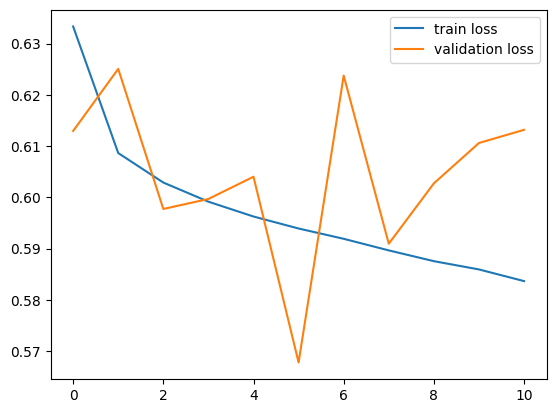

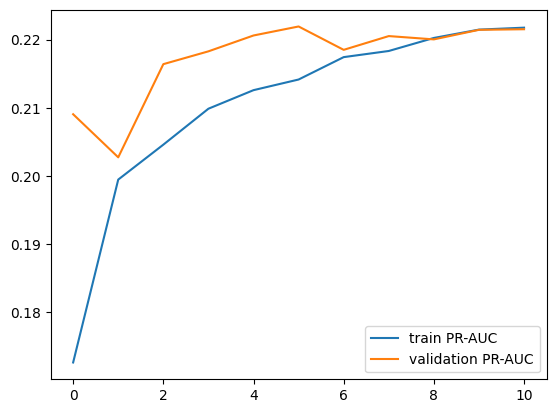

In [67]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.legend()
plt.show()

plt.plot(history.history["pr_auc"], label="train PR-AUC")
plt.plot(history.history["val_pr_auc"], label="validation PR-AUC")
plt.legend()
plt.show()

NAME_INCOME_TYPE
Maternity leave         0.400000
Unemployed              0.363636
Working                 0.095885
Commercial associate    0.074843
State servant           0.057550
Pensioner               0.053864
Businessman             0.000000
Student                 0.000000
Name: TARGET, dtype: float64


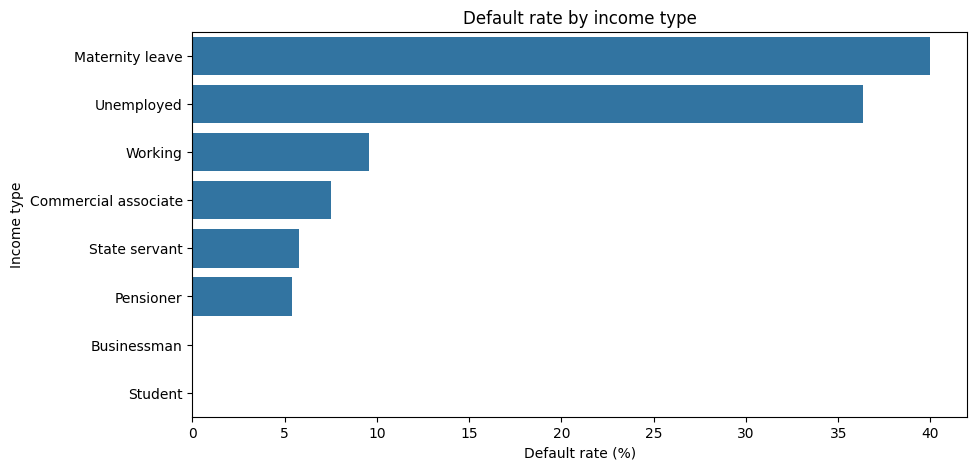

In [22]:
default_rate = (
    df.groupby("NAME_INCOME_TYPE")["TARGET"]
      .mean()
      .sort_values(ascending=False)
)

print(default_rate)
plt.figure(figsize=(10, 5))

sns.barplot(
    x=default_rate.values * 100,
    y=default_rate.index
)

plt.xlabel("Default rate (%)")
plt.ylabel("Income type")
plt.title("Default rate by income type")

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score,classification_report
from sklearn.ensemble import GradientBoostingClassifier
for n in [300,500,700]:
  for lr in [0.08,0.03,0.02,0.005]:
   
      model=Pipeline([("preprosessing",preprocessing),
                ('classifier',GradientBoostingClassifier(learning_rate=lr,n_estimators=n,subsample=0.8,min_samples_leaf=10))])
      model.fit(x_train,y_train)
      prediction=model.predict(x_validation)   
      print(f'for model:n={n},lr={lr},sb={sb},min_leaf={min_leaf}')
      print("ROC-AUC:", round(roc_auc_score(y_validation, prediction), 3))
      print("PR-AUC :", round(average_precision_score(y_validation, prediction), 3))
      print(f"classification report: {classification_report(y_validation,prediction)}")   